# Simple baselines: Claude (via the API) and colour thresholding (OpenCV)

Asks Claude to do what Raster2Seq's decoder does: look at a rendered map crop and output the **sequence of shapes** in it – each shape a list of corner points plus a label from this project's vocabulary (`VOCAB` / `CATEGORIES` in `data_preprocess/create_coco_osm.py`). The answer is then compared with the ground-truth annotations.

1. Settings and vocabulary
2. Load a target crop and one solved example crop through **Raster2Seq's own data loader** (`build_dataset`, same settings as `tools/train_osm.sh`), so Claude sees exactly the 512×512 image the Raster2Seq model sees, and the ground truth is Raster2Seq's training sequence
3. Prompt + JSON schema (the output is constrained to valid JSON with labels from the vocabulary)
4. Call Claude
5. Show the predicted sequence and score it against the ground truth
6. A **colour-threshold baseline** (OpenCV, no learning, no API) on the same image, scored the same way
7. Plot the ground truth, Claude and the baseline side by side

**Cost:** one call sends 2 images and the example's annotations (~20–40K input tokens) and gets back a few thousand to ~30K output tokens. With `claude-opus-5-5` ($4 / $20 per million input / output tokens) that is roughly **$0.20–$1 per crop**; the token usage and an estimate are printed after each call.

## 1. Settings

In [12]:
import os, subprocess, sys
import anthropic
import matplotlib.pyplot as plt
import argparse, base64, copy, io, json, collections
import numpy as np
import cv2

from skimage.morphology import skeletonize
from matplotlib.patches import Polygon as MplPolygon
from data_preprocess.create_coco_osm import CATEGORIES
from PIL import Image
from plot_floor import get_args_parser   # Raster2Seq's options (main_ddp.py's parser also imports wandb)
from datasets import build_dataset

%matplotlib inline

if not os.environ.get("ANTHROPIC_API_KEY"):
    os.environ["ANTHROPIC_API_KEY"] = subprocess.run(
        ["security", "find-generic-password", "-s", "anthropic-api", "-w"],
        capture_output=True, text=True, check=True,
    ).stdout.strip()
anthropic.Anthropic()

In [3]:
DATA = os.path.abspath("../data/coco_osm_mini")   # COCO dataset made by data_preprocess/create_coco_osm.py
TARGET_SPLIT, TARGET_IMAGE = "test", None          # file name, e.g. "queens_01156.png"; None = fewest shapes
EXAMPLE_SPLIT, EXAMPLE_IMAGE = "train", None       # worked example shown to Claude; None = fewest shapes
IMAGE_SIZE, SEQ_LEN, NUM_BINS = 512, 2048, 32      # Raster2Seq loader settings, same as tools/train_osm.sh
MODEL = "claude-opus-5-5"
EFFORT = "high"                                    # low | medium | high | xhigh | max - more effort = more careful tracing, more tokens
PRICE_IN, PRICE_OUT = 4.00, 20.00                  # $ per million tokens for claude-opus-5-5

### Vocabulary

Labels come straight from `create_coco_osm.py`, so this notebook always uses the same vocabulary as the training data. Each label is either a closed polygon or an open line (the vocabulary keeps the two apart).

In [4]:
sys.path[:0] = [os.path.abspath("../../Raster2Seq"), os.path.abspath("..")]

LINE_LABELS = {"highway", "street", "path", "railway", "pier", "waterway", "runway", "unknown_line"}
NAMES = {i: name for name, i in CATEGORIES.items()}

# What each label looks like in the rendered maps (OSM Carto style, approximate colours)
LABEL_HINTS = {
    "building": "building footprint; grey-beige block with a darker outline",
    "highway": "motorway / trunk road centreline; thick pink-red or orange-red road",
    "street": "other road centreline (primary orange, secondary yellow, smaller roads white with grey edges)",
    "path": "footpath / track centreline; thin dashed or dotted line (often salmon or brown)",
    "plaza": "pedestrian area; light grey-lilac area",
    "railway": "rail / subway / tram centreline; grey line, often with white dashes",
    "rail_yard": "railway land; light purple area around tracks",
    "bridge": "bridge deck area",
    "pier": "pier centreline",
    "pier_area": "pier area over water; pale grey area",
    "water": "lake, pond, river or ocean area; blue",
    "pool": "swimming pool; small blue shape, usually in a back yard",
    "waterway": "stream / river / canal / ditch centreline; blue line",
    "park": "park or protected area; light green area, sometimes only a green outline",
    "playground": "playground; very light green area",
    "sports_field": "pitch, running track or stadium; turquoise-green area",
    "grass": "grass area; light green",
    "woods": "wooded area; darker green",
    "wetland": "wetland; green with a blue reed pattern",
    "bare_ground": "sand or rock; beige / light brown area",
    "school": "school, college or university grounds; pale yellow area",
    "hospital": "hospital grounds; pale yellow area",
    "civic": "library or bus station grounds",
    "cemetery": "cemetery; grey-green area",
    "residential": "residential land use; light grey background area under houses",
    "commercial": "commercial land use; pale pink area",
    "retail": "retail land use; stronger pink area",
    "industrial": "industrial land use; light purple area",
    "airport": "airport grounds / apron",
    "runway": "runway or taxiway centreline",
    "runway_area": "runway drawn as an area; grey strip",
    "unknown": "any other polygon feature",
    "unknown_line": "any other line feature (ferry route, cliff edge, ...)",
}
assert set(LABEL_HINTS) == set(CATEGORIES), set(CATEGORIES) ^ set(LABEL_HINTS)

## 2. Load crops through Raster2Seq's data loader

`build_dataset` is the loader Raster2Seq trains with. For each crop it resizes and pads the image to `IMAGE_SIZE`×`IMAGE_SIZE` (white padding, because of `--dataset_name waffle`), sorts the shapes, and builds the token sequence. The ground truth below is decoded from that sequence (`target_seq` + `token_labels` + `target_polygon_labels`), so it has Raster2Seq's shape order and loses any shapes past `SEQ_LEN`, exactly like a training target.

**Lines:** the loader also reorders every shape's points to start near the top-left (`resort_corners`), which scrambles open lines (streets, paths, rails, …) in Raster2Seq's training targets. Below, each line's start → finish order is restored from the annotation so Claude is scored against the real line; polygons are used as the loader produces them.

In [5]:
def make_dataset(split):
    args = argparse.ArgumentParser(parents=[get_args_parser()]).parse_args([
        "--dataset_name", "waffle", "--dataset_root", DATA, "--eval_set", split,
        "--semantic_classes", str(len(CATEGORIES) + 1), "--input_channels", "3", "--poly2seq",
        "--seq_len", str(SEQ_LEN), "--num_bins", str(NUM_BINS), "--image_size", str(IMAGE_SIZE), "--row_tolerance", "0.08",  # rows 8% of the image height (reading order)
        "--disable_image_transform",   # no random flips/rotations
    ])
    ds = build_dataset(image_set=split, args=args)
    load_anns = ds.coco.loadAnns     # Raster2Seq's loader edits annotations in place; hand it copies
    ds.coco.loadAnns = lambda ids: copy.deepcopy(load_anns(ids))
    return ds

def pick(split, file_name):
    ds = make_dataset(split)
    n_anns = [len(ds.coco.getAnnIds(imgIds=i)) for i in ds.ids]
    if file_name is None:   # fewest shapes = cheapest call
        k = int(np.argmin(n_anns))
    else:
        k = next(k for k, i in enumerate(ds.ids) if ds.coco.loadImgs(i)[0]["file_name"] == file_name)
    r = ds[k]
    img = Image.fromarray((r["image"].permute(1, 2, 0).numpy() * 255).round().astype(np.uint8))

    # decode the training sequence: corners (token 0) until a separator / end token
    n = int(r["mask"].sum())
    xy = (r["target_seq"][:n] * (img.width - 1)).tolist()
    parts, cur = [], []
    for p, t in zip(xy, r["token_labels"][:n].tolist()):
        if t == 0:
            cur.append([round(p[0], 1), round(p[1], 1)])
        else:
            parts.append(cur)
            cur = []
    labels = [l for l in r["target_polygon_labels"].tolist() if l != -1]
    shapes = [{"label": NAMES[l], "points": pts} for l, pts in zip(labels, parts)]

    # The loader runs resort_corners on every shape, which rotates an open line's points to start near
    # the top-left and so splices its end onto its start. Restore each line's start -> finish order from
    # the annotation, resized and padded exactly like the loader's ResizeAndPad (and clipped like target_seq).
    info = ds.coco.loadImgs(ds.ids[k])[0]
    S, h, w = img.width, info["height"], info["width"]
    sc = min(S / h, S / w)
    nh, nw = int(h * sc), int(w * sc)
    originals = []
    for a in ds.coco.loadAnns(ds.coco.getAnnIds(imgIds=ds.ids[k])):
        if a.get("geom_type") == "line":
            pts = np.reshape(a["segmentation"][0], (-1, 2)) * [nw / w, nh / h] + [(S - nw) // 2, (S - nh) // 2]
            originals.append(np.clip(pts, 0, S - 1))
    for s in shapes:
        if s["label"] in LINE_LABELS:
            got = np.array(s["points"])
            for o in originals:   # same points, possibly in another order
                if len(o) == len(got) and np.abs(np.sort(o, axis=0) - np.sort(got, axis=0)).max() < 0.6:
                    s["points"] = o.round(1).tolist()
                    break
    return {"name": ds.coco.loadImgs(ds.ids[k])[0]["file_name"], "image": img, "shapes": shapes,
            "n_annotations": n_anns[k], "n_tokens": n}

def as_image_block(img):
    buf = io.BytesIO()
    img.save(buf, format="PNG")
    return {"type": "image", "source": {"type": "base64", "media_type": "image/png",
                                        "data": base64.standard_b64encode(buf.getvalue()).decode()}}

target = pick(TARGET_SPLIT, TARGET_IMAGE)
example = pick(EXAMPLE_SPLIT, EXAMPLE_IMAGE)
for name, d in [("target", target), ("example", example)]:
    print(f"{name}: {d['name']} | {d['image'].width}x{d['image'].height} px | {len(d['shapes'])} of "
          f"{d['n_annotations']} shapes fit in the {SEQ_LEN}-token sequence ({d['n_tokens']} tokens)")

Build waffle test dataset
loading annotations into memory...
Done (t=0.01s)
creating index...
index created!
Build waffle train dataset
loading annotations into memory...
Done (t=0.02s)
creating index...
index created!
target: queens_10498.png | 512x512 px | 79 of 79 shapes fit in the 2048-token sequence (487 tokens)
example: staten_island_12890.png | 512x512 px | 16 of 16 shapes fit in the 2048-token sequence (152 tokens)


## 3. Prompt and output schema

The system prompt describes the task the way Raster2Seq frames it: one sequence of shapes in the order Raster2Seq's converter produces (`ConvertToCocoDictWithOrder_plus`: left to right by each shape's topmost point), polygons starting at the corner nearest the top-left and running counterclockwise (`resort_corners`). The image has white padding bars from the loader's resize-and-pad. The JSON schema restricts `label` to the vocabulary.

In [6]:
SYSTEM_PROMPT = f"""You vectorize rendered street-map images (OpenStreetMap data drawn in the standard OSM style).

Given a map image, list every map feature you can see as a shape with a label and pixel coordinates:
- Coordinates are [x, y] in pixels of the image you are given; (0, 0) is the top-left corner, x grows to the right, y grows downward.
- Polygon labels: give the outline's corner points once each, without repeating the first point at the end. Start at the corner nearest the image's top-left and go counterclockwise as seen on screen.
- Line labels ({", ".join(sorted(LINE_LABELS))}): give the centreline from one end to the other. Roads and paths are lines, not areas.
- Order the shapes left to right by the x coordinate of each shape's topmost point.
- The map may have white padding bars at the top/bottom or sides; there are no features in them. Shapes that run off the map edge stop at the edge.
- Ignore text labels, icons and house numbers - they are not features.
- Large background areas (residential, park, school grounds) are shapes too, even when buildings sit on top of them.

Labels:
""" + "\n".join(f"- {label} ({'line' if label in LINE_LABELS else 'polygon'}): {hint}" for label, hint in LABEL_HINTS.items())

SCHEMA = {
    "type": "object",
    "properties": {
        "shapes": {
            "type": "array",
            "items": {
                "type": "object",
                "properties": {
                    "label": {"type": "string", "enum": list(CATEGORIES)},
                    "points": {"type": "array", "items": {"type": "array", "items": {"type": "number"}}},
                },
                "required": ["label", "points"],
                "additionalProperties": False,
            },
        }
    },
    "required": ["shapes"],
    "additionalProperties": False,
}

def size_note(d):
    return f"The image is {d['image'].width} x {d['image'].height} pixels."

messages = [{"role": "user", "content": [
    {"type": "text", "text": "Worked example - an input map:"},
    as_image_block(example["image"]),
    {"type": "text", "text": size_note(example) + " Its correct answer:\n" + json.dumps({"shapes": example["shapes"]}),
     "cache_control": {"type": "ephemeral"}},   # system prompt + example are cached across calls
    {"type": "text", "text": "Now vectorize this map the same way:"},
    as_image_block(target["image"]),
    {"type": "text", "text": size_note(target)},
]}]
print(f"system prompt: {len(SYSTEM_PROMPT)} characters | example answer: {len(json.dumps(example['shapes']))} characters")

system prompt: 3262 characters | example answer: 2599 characters


## 4. Call Claude

Streaming (the answer can be long), adaptive thinking, and `output_config.format` so the answer is guaranteed to be JSON matching the schema. `fallbacks="default"` is enabled: if Claude Opus 5.5's safety classifiers decline the request, the API re-runs it on Anthropic's recommended fallback model instead of returning a refusal (unlikely for maps, but cheap insurance).

In [7]:
client = anthropic.Anthropic()

def predict_with_claude(messages):
    with client.beta.messages.stream(
        model=MODEL,
        max_tokens=64000,
        betas=["server-side-fallback-2026-07-01"],
        fallbacks="default",
        thinking={"type": "adaptive"},
        output_config={"effort": EFFORT, "format": {"type": "json_schema", "schema": SCHEMA}},
        system=SYSTEM_PROMPT,
        messages=messages,
    ) as stream:
        response = stream.get_final_message()

    u = response.usage
    cost = (u.input_tokens + 1.25 * (u.cache_creation_input_tokens or 0) + 0.1 * (u.cache_read_input_tokens or 0)) \
        * PRICE_IN / 1e6 + u.output_tokens * PRICE_OUT / 1e6
    print(f"served by {response.model} | stop_reason {response.stop_reason} | input {u.input_tokens} "
          f"(+{u.cache_creation_input_tokens or 0} cache write, {u.cache_read_input_tokens or 0} cache read) | "
          f"output {u.output_tokens} tokens | ~${cost:.2f}")

    if response.stop_reason == "refusal":
        raise RuntimeError(f"Refused: {response.stop_details}")
    if response.stop_reason == "max_tokens":
        raise RuntimeError("Answer was cut off at max_tokens - try a crop with fewer shapes or lower EFFORT")
    text = next(b.text for b in response.content if b.type == "text")
    return json.loads(text)["shapes"]

pred_shapes = predict_with_claude(messages)

served by claude-opus-5-5 | stop_reason end_turn | input 395 (+3675 cache write, 0 cache read) | output 1137 tokens | ~$0.04


## 5. Results

### The predicted sequence

In [8]:
def clean(shapes):
    """Keep well-formed shapes: [x, y] points, >= 3 for polygons and >= 2 for lines."""
    out = []
    for s in shapes:
        pts = [p for p in s["points"] if len(p) == 2]
        if len(pts) >= (2 if s["label"] in LINE_LABELS else 3):
            out.append({"label": s["label"], "points": pts})
    return out

pred = clean(pred_shapes)
print(f"{len(pred)} predicted shapes ({len(pred_shapes) - len(pred)} malformed dropped) "
      f"vs {len(target['shapes'])} in the ground truth\n")
for i, s in enumerate(pred[:15]):
    pts = " ".join(f"({x:.0f},{y:.0f})" for x, y in s["points"])
    print(f"{i + 1:>3}. {s['label']:<13} {pts}")
if len(pred) > 15:
    print(f"... {len(pred) - 15} more")

20 predicted shapes (0 malformed dropped) vs 79 in the ground truth

  1. highway       (56,0) (120,150) (180,290) (240,420) (275,512)
  2. highway       (82,0) (150,160) (210,310) (260,410) (315,512)
  3. street        (53,60) (100,170) (150,290) (200,400) (228,512)
  4. street        (80,195) (100,215) (140,280) (168,350)
  5. highway       (168,355) (200,420) (240,512)
  6. street        (53,130) (100,240) (150,380) (200,512)
  7. path          (53,410) (100,460) (160,512)
  8. path          (53,450) (80,512)
  9. woods         (110,0) (150,60) (210,150) (235,210) (250,265) (290,290) (310,360) (340,460) (355,512) (340,512) (310,460) (290,400) (270,330) (235,270) (220,210) (200,150) (150,70) (120,30)
 10. park          (140,0) (459,0) (459,480) (360,505) (330,440) (300,370) (280,285) (250,270) (240,170) (200,80) (175,40)
 11. path          (258,18) (335,22)
 12. path          (265,76) (328,80)
 13. path          (357,0) (348,120)
 14. street        (178,0) (220,80) (255,175) (250,240

### Score against the ground truth

Polygons are matched one-to-one within each label by overlap (IoU ≥ 0.5, greedy, best pairs first). Lines are compared after widening both to 6-pixel bands. Precision = share of predicted shapes that match a real one; recall = share of real shapes that were found.

In [9]:
from shapely.geometry import LineString, Polygon

def geometry(s):
    if s["label"] in LINE_LABELS:
        return LineString(s["points"]).buffer(3)
    return Polygon(s["points"]).buffer(0)

def match(preds, gts, thr=0.5):
    pairs = []
    for i, p in enumerate(preds):
        for j, g in enumerate(gts):
            if p["label"] != g["label"]:
                continue
            a, b = geometry(p), geometry(g)
            union = a.union(b).area
            if union > 0:
                pairs.append((a.intersection(b).area / union, i, j))
    used_p, used_g, hits = set(), set(), collections.Counter()
    for iou, i, j in sorted(pairs, reverse=True):
        if iou < thr:
            break
        if i not in used_p and j not in used_g:
            used_p.add(i); used_g.add(j); hits[preds[i]["label"]] += 1
    return hits

def score(pred, gt):
    hits = match(pred, gt)
    n_pred, n_gt = collections.Counter(s["label"] for s in pred), collections.Counter(s["label"] for s in gt)
    print(f"{'label':<13} {'pred':>5} {'true':>5} {'match':>6} {'precision':>10} {'recall':>7}")
    for label in sorted(set(n_pred) | set(n_gt), key=lambda l: -n_gt[l]):
        p, g, h = n_pred[label], n_gt[label], hits[label]
        print(f"{label:<13} {p:>5} {g:>5} {h:>6} {h / p if p else 0:>10.2f} {h / g if g else 0:>7.2f}")
    P, G, H = sum(n_pred.values()), sum(n_gt.values()), sum(hits.values())
    print(f"{'all':<13} {P:>5} {G:>5} {H:>6} {H / P if P else 0:>10.2f} {H / G if G else 0:>7.2f}")

gt = target["shapes"]
score(pred, gt)

label          pred  true  match  precision  recall
path              5    19      2       0.40    0.11
street            9    18      4       0.44    0.22
grass             0    17      0       0.00    0.00
highway           3    11      0       0.00    0.00
building          0     4      0       0.00    0.00
water             1     2      0       0.00    0.00
residential       0     2      0       0.00    0.00
wetland           0     2      0       0.00    0.00
woods             1     2      0       0.00    0.00
cemetery          0     2      0       0.00    0.00
park              1     0      0       0.00    0.00
all              20    79      6       0.30    0.08


## 6. Color-threshold baseline (OpenCV, no learning)

The crops are drawn with a fixed palette (`utils/render_carto.py`), so most labels can be found by Color alone:
1. **Pixels → mask:** pixels within `TOL` of a label's Color (the loader's resizing blends Colors at edges, hence a tolerance). The white padding bars are excluded.
2. **Polygons:** `cv2.findContours` traces each region's outline; `cv2.approxPolyDP` keeps the corners. Blue areas smaller than `POOL_MAX` px² become `pool`, larger ones `water`.
3. **Lines:** the road mask is thinned to 1-pixel centrelines (`skeletonize`), split at junctions, and each piece is traced end to end and simplified.

Known blind spots, by design: labels that share a Color (`industrial` / `rail_yard`, `school` / `hospital` / `civic`, `waterway` vs. `water`), features covered by text, dotted paths, parks drawn only as an outline, and anything outside the palette. White streets also pick up white text halos.

In [10]:
TOL = 12          # max per-channel colour difference (0-255)
POOL_MAX = 300    # blue areas smaller than this (px^2 at IMAGE_SIZE) are pools
POLY_COLORS = {   # label -> render colours (utils/render_carto.py)
    "building": ["#d9d0c9"], "grass": ["#cdebb0"], "park": ["#c8facc"], "woods": ["#add19e"],
    "playground": ["#dffce2"], "sports_field": ["#aae0cb"], "cemetery": ["#aacbaf"], "school": ["#ffffe5"],
    "residential": ["#e0dfdf"], "commercial": ["#f2dad9"], "retail": ["#ffd6d1"], "industrial": ["#ebdbe8"],
    "bare_ground": ["#f5e9c6", "#eee5dc"], "plaza": ["#dddde8"],
}
WATER_COLOR = "#aad3df"   # water and pool share it
LINE_COLORS = {"highway": ["#e892a2", "#f9b29c"], "street": ["#fcd6a4", "#f7fabf", "#ffffff"],
               "railway": ["#707070", "#787878"], "path": ["#fa8072"]}

def color_mask(arr, hexes):
    m = np.zeros(arr.shape[:2], bool)
    for h in hexes:
        rgb = np.array([int(h[i:i + 2], 16) for i in (1, 3, 5)])
        m |= np.abs(arr.astype(int) - rgb).max(-1) <= TOL
    return m

def content_area(arr):
    """The loader pads with pure white; keep the box spanned by rows/columns that aren't all white."""
    not_white = ~(arr == 255).all(-1)
    rows, cols = np.flatnonzero(not_white.any(1)), np.flatnonzero(not_white.any(0))
    box = np.zeros(arr.shape[:2], bool)
    box[rows[0]:rows[-1] + 1, cols[0]:cols[-1] + 1] = True
    return box

def mask_to_polygons(m, min_area=20, eps=1.5):
    m = cv2.morphologyEx(m.astype(np.uint8), cv2.MORPH_OPEN, np.ones((2, 2), np.uint8))  # drop specks
    contours, _ = cv2.findContours(m, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    out = []
    for c in contours:
        if cv2.contourArea(c) >= min_area:
            pts = cv2.approxPolyDP(c, eps, True).reshape(-1, 2)
            if len(pts) >= 3:
                out.append((cv2.contourArea(c), pts.astype(float).tolist()))
    return out

def trace(pixels):
    """Order the pixels of a 1-pixel-wide path from one end to the other."""
    nbrs = lambda p: [(p[0] + dx, p[1] + dy) for dx in (-1, 0, 1) for dy in (-1, 0, 1)
                      if (dx or dy) and (p[0] + dx, p[1] + dy) in pixels]
    path = [next((p for p in pixels if len(nbrs(p)) == 1), next(iter(pixels)))]
    seen = {path[0]}
    while nxt := [q for q in nbrs(path[-1]) if q not in seen]:
        path.append(nxt[0])
        seen.add(nxt[0])
    return path

def mask_to_lines(m, min_len=8, eps=1.5):
    sk = skeletonize(m)
    n_nbrs = cv2.filter2D(sk.astype(np.float32), -1, np.ones((3, 3), np.float32)) - sk
    sk &= ~(n_nbrs > 2)                        # cut at junctions -> simple paths
    n, comp = cv2.connectedComponents(sk.astype(np.uint8), connectivity=8)
    out = []
    for i in range(1, n):
        ys, xs = np.nonzero(comp == i)
        if len(xs) >= min_len:
            path = np.array(trace(set(zip(xs.tolist(), ys.tolist()))), np.int32).reshape(-1, 1, 2)
            out.append(cv2.approxPolyDP(path, eps, False).reshape(-1, 2).astype(float).tolist())
    return out

def cv2_baseline(img):
    arr = np.array(img)
    inside = content_area(arr)
    shapes = []
    for label, hexes in POLY_COLORS.items():
        shapes += [{"label": label, "points": pts} for _, pts in mask_to_polygons(color_mask(arr, hexes) & inside)]
    for area, pts in mask_to_polygons(color_mask(arr, [WATER_COLOR]) & inside):
        shapes.append({"label": "pool" if area < POOL_MAX else "water", "points": pts})
    for label, hexes in LINE_COLORS.items():
        shapes += [{"label": label, "points": pts} for pts in mask_to_lines(color_mask(arr, hexes) & inside)]
    return shapes

cv_pred = cv2_baseline(target["image"])
print(f"{len(cv_pred)} shapes from the colour-threshold baseline\n")
score(cv_pred, gt)

61 shapes from the colour-threshold baseline

label          pred  true  match  precision  recall
path              0    19      0       0.00    0.00
street           10    18      2       0.20    0.11
grass            10    17      7       0.70    0.41
highway           7    11      2       0.29    0.18
building          1     4      0       0.00    0.00
water             1     2      0       0.00    0.00
residential       1     2      0       0.00    0.00
wetland           0     2      0       0.00    0.00
woods             1     2      1       1.00    0.50
cemetery         11     2      0       0.00    0.00
industrial        1     0      0       0.00    0.00
park             17     0      0       0.00    0.00
plaza             1     0      0       0.00    0.00
all              61    79     12       0.20    0.15


### Plot: ground truth vs. Claude vs. the baseline

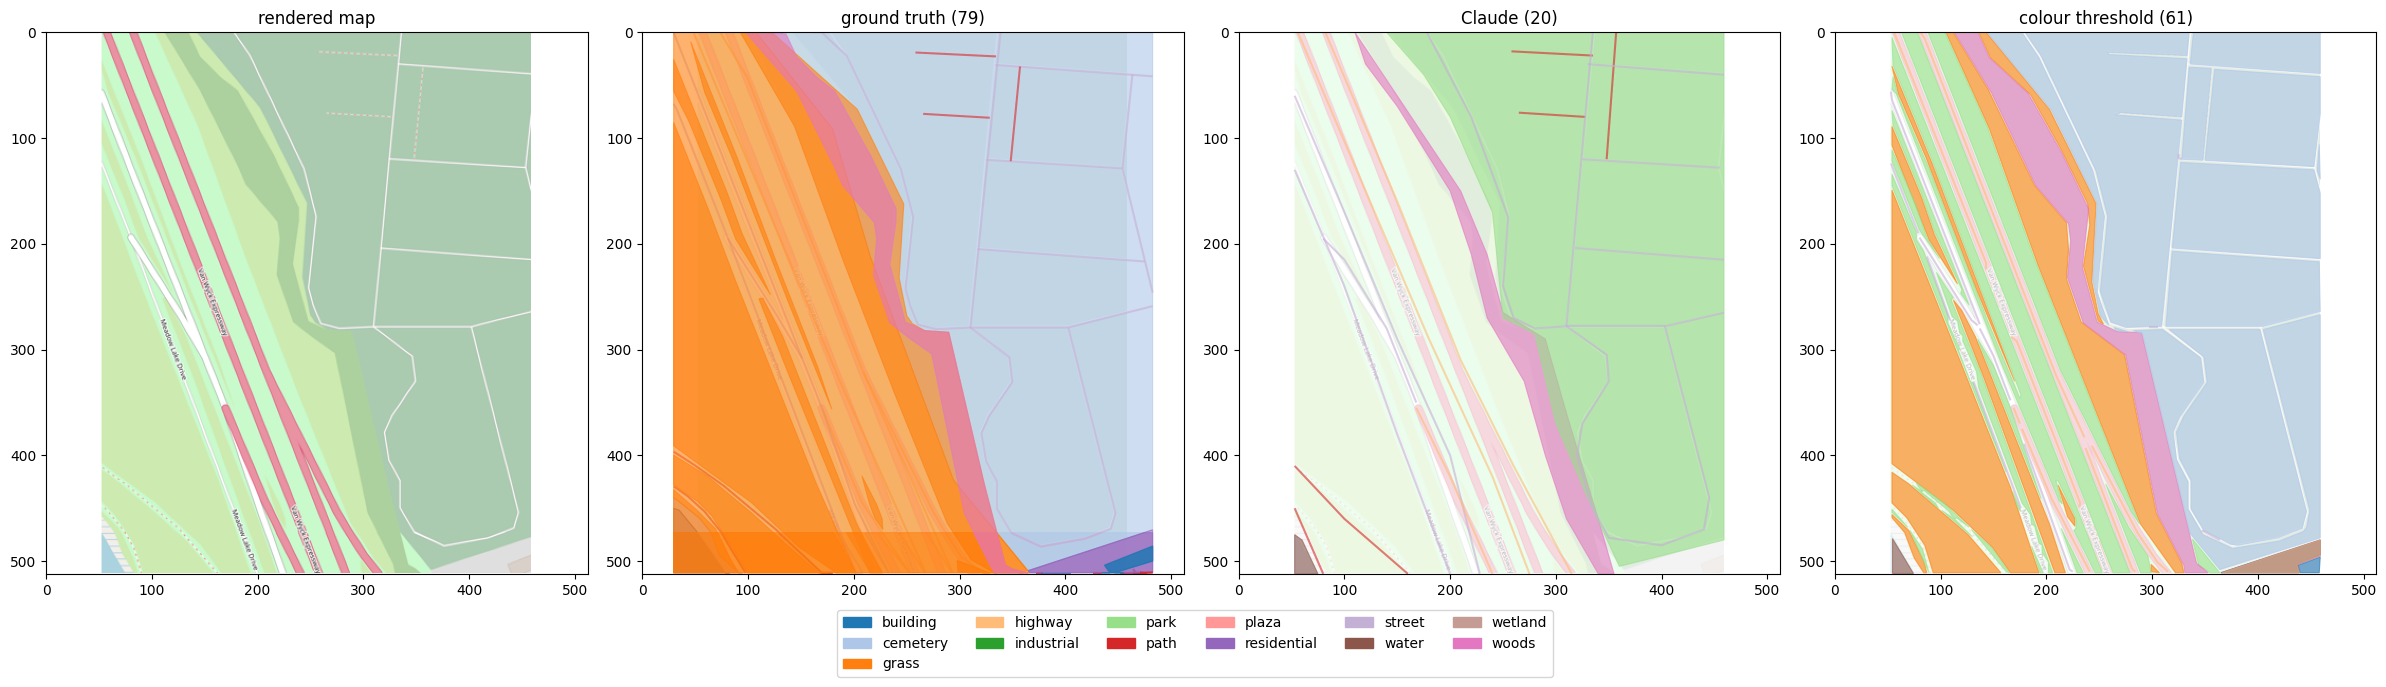

In [14]:
W, H = target["image"].size
labels = sorted({s["label"] for s in gt + globals().get("pred", []) + cv_pred})
colors = {l: plt.cm.tab20(i % 20) for i, l in enumerate(labels)}

panels = [("rendered map", None), (f"ground truth ({len(gt)})", gt)]
if "pred" in globals():   # Claude's answer, if section 4 ran
    panels.append((f"Claude ({len(pred)})", pred))
panels.append((f"colour threshold ({len(cv_pred)})", cv_pred))
fig, axes = plt.subplots(1, len(panels), figsize=(6 * len(panels), 6))
for ax, (title, shapes) in zip(axes, panels):
    ax.imshow(target["image"], alpha=1 if shapes is None else 0.35)
    for s in shapes or []:
        is_poly = s["label"] not in LINE_LABELS
        ax.add_patch(MplPolygon(s["points"], closed=is_poly, fill=is_poly, facecolor=colors[s["label"]],
                                edgecolor=colors[s["label"]], alpha=0.6, linewidth=0.8 if is_poly else 1.5))
    ax.set(title=title, xlim=(0, W), ylim=(H, 0), aspect="equal")
plt.tight_layout()
fig.legend([plt.Rectangle((0, 0), 1, 1, color=colors[l]) for l in labels], labels,
           loc="upper center", bbox_to_anchor=(0.5, 0), ncol=6)
plt.show();

## Next steps

- Try other crops (`TARGET_IMAGE`), more effort (`EFFORT = "xhigh"`), or more worked examples.
- Larger crops have hundreds of shapes; splitting a crop into tiles keeps each answer shorter and more precise.
- `IMAGE_SIZE = 1024` gives Claude more detail than Raster2Seq's 512 (Claude accepts up to ~1,500 px per side).
- To compare with Raster2Seq, run it on the same test crops and score it with the same `score()` function.
- The baseline's `TOL`, `POOL_MAX` and colour lists are hand-set; try a grayscale image (`target["image"].convert("L").convert("RGB")`) to see how much of its score depends on colour.